In [1]:
import pandas as pd
import numpy as np
import joblib

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
xgb_model = joblib.load("../models/xgboost.pkl")

X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print("Model and test data loaded successfully!")
print("Test data shape:", X_test.shape)

Model and test data loaded successfully!
Test data shape: (154, 8)


In [3]:
lime_df = pd.read_csv("../results/lime_values.csv")

lime_df

,Feature,Contribution
0,Glucose > 0.61,0.460678
1,BMI <= -0.71,-0.207388
2,Pregnancies > 0.66,0.068405
3,-0.22 < Insulin <= -0.16,0.047040
4,-0.70 < DiabetesPedigreeFunction <= -0.29,-0.043436
5,-0.37 < Age <= 0.65,0.031677
6,BloodPressure <= -0.66,-0.012071
7,-0.45 < SkinThickness <= -0.00,-0.005983


In [4]:
shap_df = pd.read_csv("../results/shap_values.csv")

print("SHAP values loaded successfully!")
print("SHAP shape:", shap_df.shape)

shap_df.head()

SHAP values loaded successfully!
SHAP shape: (154, 8)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.457175,2.203508,0.090202,-0.013093,0.234807,-0.226216,-0.309673,0.306280
1,0.286508,-2.307677,-0.137943,-0.135342,-0.949151,0.053799,-0.550458,0.610588
2,-0.130691,-0.707896,0.013827,-0.079687,-0.266432,0.116407,-0.120572,-0.499502
3,0.249521,-0.186082,0.203620,-0.013320,0.170256,0.022033,0.494412,0.253050
4,-0.162379,-2.708208,0.073204,-0.149422,0.153259,0.332213,-1.023390,-0.438819


In [5]:
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("First 10 predictions:", y_pred[:10])
print("First 10 probabilities:", y_prob[:10])

Predictions generated successfully!
First 10 predictions: [1 0 0 1 0 0 0 1 0 1]
First 10 probabilities: [0.8917195  0.02265984 0.09037137 0.63620436 0.01037316 0.22286052
 0.4698643  0.9295457  0.10533553 0.9606476 ]


In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Model Performance")
print("------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Model Performance
------------------
Accuracy : 0.7597
Precision: 0.6735
Recall   : 0.6111
F1 Score : 0.6408
ROC-AUC  : 0.827


In [7]:
lime_importance = (
    lime_df.groupby("Feature")["Contribution"]
    .apply(lambda x: x.abs().mean())
    .sort_values(ascending=False)
)

print("Global LIME Feature Importance")
print("--------------------------------")
print(lime_importance)

Global LIME Feature Importance
--------------------------------
Feature
Glucose > 0.61                               0.460678
BMI <= -0.71                                 0.207388
Pregnancies > 0.66                           0.068405
-0.22 < Insulin <= -0.16                     0.047040
-0.70 < DiabetesPedigreeFunction <= -0.29    0.043436
-0.37 < Age <= 0.65                          0.031677
BloodPressure <= -0.66                       0.012071
-0.45 < SkinThickness <= -0.00               0.005983
Name: Contribution, dtype: float64


In [9]:
shap_df = pd.read_csv("../results/shap_values.csv")

shap_importance = shap_df.abs().mean().sort_values(ascending=False)

print("Global SHAP Feature Importance")
print("--------------------------------")
print(shap_importance)

Global SHAP Feature Importance
--------------------------------
Glucose                     1.147666
BMI                         0.664666
DiabetesPedigreeFunction    0.393545
Age                         0.325351
Insulin                     0.264608
Pregnancies                 0.203174
BloodPressure               0.117383
SkinThickness               0.100768
dtype: float64


In [10]:
lime_importance = (
    lime_df.groupby("Feature")["Contribution"]
    .apply(lambda x: x.abs().mean())
    .sort_values(ascending=False)
)

print("Global LIME Feature Importance")
print("--------------------------------")
print(lime_importance)

Global LIME Feature Importance
--------------------------------
Feature
Glucose > 0.61                               0.460678
BMI <= -0.71                                 0.207388
Pregnancies > 0.66                           0.068405
-0.22 < Insulin <= -0.16                     0.047040
-0.70 < DiabetesPedigreeFunction <= -0.29    0.043436
-0.37 < Age <= 0.65                          0.031677
BloodPressure <= -0.66                       0.012071
-0.45 < SkinThickness <= -0.00               0.005983
Name: Contribution, dtype: float64


In [11]:
print("Top 5 SHAP Features:")
print(shap_importance.head(5).index.tolist())

print("\nTop 5 LIME Features:")
print(lime_importance.head(5).index.tolist())

Top 5 SHAP Features:
['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Insulin']

Top 5 LIME Features:
['Glucose > 0.61', 'BMI <= -0.71', 'Pregnancies > 0.66', '-0.22 < Insulin <= -0.16', '-0.70 < DiabetesPedigreeFunction <= -0.29']


In [12]:
comparison_features = [
    "Glucose",
    "BMI",
    "DiabetesPedigreeFunction",
    "Insulin",
    "Pregnancies",
    "Age"
]

shap_values = [
    shap_importance.get("Glucose", 0),
    shap_importance.get("BMI", 0),
    shap_importance.get("DiabetesPedigreeFunction", 0),
    shap_importance.get("Insulin", 0),
    shap_importance.get("Pregnancies", 0),
    shap_importance.get("Age", 0)
]

lime_values = []

for feature in comparison_features:
    matching = lime_importance[
        lime_importance.index.str.contains(feature, regex=False)
    ]
    
    if len(matching) > 0:
        lime_values.append(matching.iloc[0])
    else:
        lime_values.append(0)

comparison_df = pd.DataFrame({
    "Feature": comparison_features,
    "SHAP": shap_values,
    "LIME": lime_values
})

comparison_df

,Feature,SHAP,LIME
0,Glucose,1.147666,0.460678
1,BMI,0.664666,0.207388
2,DiabetesPedigreeFunction,0.393545,0.043436
3,Insulin,0.264608,0.047040
4,Pregnancies,0.203174,0.068405
5,Age,0.325351,0.031677


NameError: name 'plt' is not defined

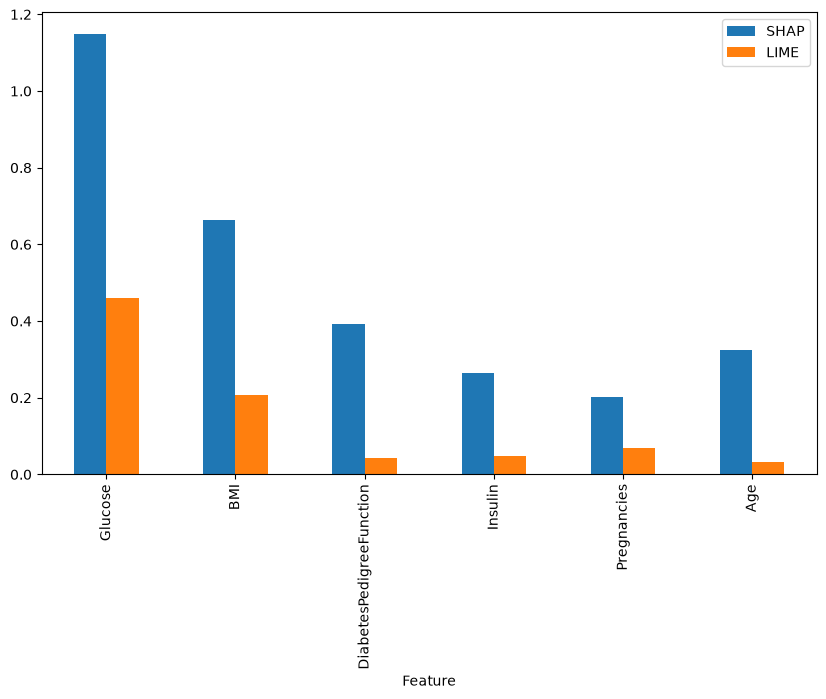

In [13]:
comparison_df.set_index("Feature")[["SHAP", "LIME"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SHAP vs LIME Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
import matplotlib.pyplot as plt

print("Matplotlib loaded successfully!")

Matplotlib loaded successfully!


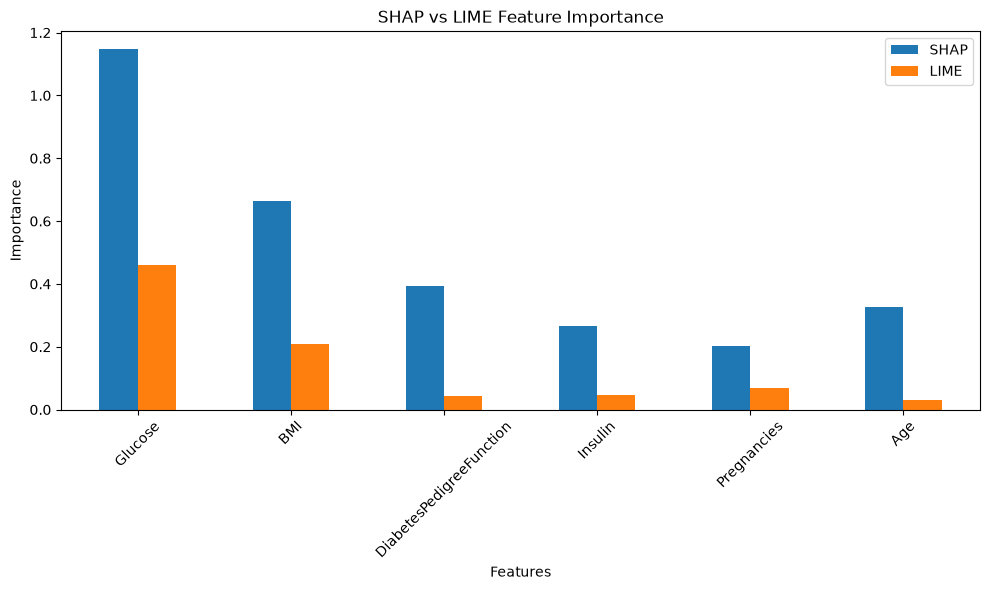

In [15]:
comparison_df.set_index("Feature")[["SHAP", "LIME"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SHAP vs LIME Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
comparison_df.to_csv("../results/shap_lime_comparison.csv", index=False)

print("SHAP vs LIME comparison saved successfully!")

SHAP vs LIME comparison saved successfully!


In [17]:
from scipy.stats import spearmanr

shap_ranks = comparison_df["SHAP"].rank(ascending=False)
lime_ranks = comparison_df["LIME"].rank(ascending=False)

correlation, p_value = spearmanr(shap_ranks, lime_ranks)

print("SHAP-LIME Rank Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

SHAP-LIME Rank Correlation: 0.4857
P-value: 0.3287


In [18]:
print("========== TRUST EVALUATION SUMMARY ==========")

print("\nModel Performance:")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

print("\nTop SHAP Features:")
print(shap_importance.head(5).index.tolist())

print("\nTop LIME Features:")
print(lime_importance.head(5).index.tolist())

print("\nSHAP-LIME Correlation:", round(correlation, 4))

========== TRUST EVALUATION SUMMARY ==========

Model Performance:
Accuracy : 0.7597
Precision: 0.6735
Recall   : 0.6111
F1 Score : 0.6408
ROC-AUC  : 0.827

Top SHAP Features:
['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Insulin']

Top LIME Features:
['Glucose > 0.61', 'BMI <= -0.71', 'Pregnancies > 0.66', '-0.22 < Insulin <= -0.16', '-0.70 < DiabetesPedigreeFunction <= -0.29']

SHAP-LIME Correlation: 0.4857


In [19]:
from scipy.stats import spearmanr

shap_ranks = comparison_df["SHAP"].rank(ascending=False)
lime_ranks = comparison_df["LIME"].rank(ascending=False)

correlation, p_value = spearmanr(shap_ranks, lime_ranks)

print("SHAP-LIME Rank Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

SHAP-LIME Rank Correlation: 0.4857
P-value: 0.3287


In [20]:
print("========== TRUST EVALUATION ==========")

print("\nTop 5 SHAP Features:")
print(shap_importance.head(5).index.tolist())

print("\nTop 5 LIME Features:")
print(lime_importance.head(5).index.tolist())

print("\nSHAP-LIME Rank Correlation:", round(correlation, 4))

========== TRUST EVALUATION ==========

Top 5 SHAP Features:
['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Insulin']

Top 5 LIME Features:
['Glucose > 0.61', 'BMI <= -0.71', 'Pregnancies > 0.66', '-0.22 < Insulin <= -0.16', '-0.70 < DiabetesPedigreeFunction <= -0.29']

SHAP-LIME Rank Correlation: 0.4857


In [21]:
from scipy.stats import spearmanr

shap_ranks = comparison_df["SHAP"].rank(ascending=False)
lime_ranks = comparison_df["LIME"].rank(ascending=False)

correlation, p_value = spearmanr(shap_ranks, lime_ranks)

print("SHAP-LIME Rank Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

SHAP-LIME Rank Correlation: 0.4857
P-value: 0.3287


In [22]:
print("========== TRUST EVALUATION ==========")

print("\nTop 5 SHAP Features:")
print(shap_importance.head(5).index.tolist())

print("\nTop 5 LIME Features:")
print(lime_importance.head(5).index.tolist())

print("\nSHAP-LIME Rank Correlation:", round(correlation, 4))

========== TRUST EVALUATION ==========

Top 5 SHAP Features:
['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Insulin']

Top 5 LIME Features:
['Glucose > 0.61', 'BMI <= -0.71', 'Pregnancies > 0.66', '-0.22 < Insulin <= -0.16', '-0.70 < DiabetesPedigreeFunction <= -0.29']

SHAP-LIME Rank Correlation: 0.4857


In [23]:
from scipy.stats import spearmanr

shap_ranks = comparison_df["SHAP"].rank(ascending=False)
lime_ranks = comparison_df["LIME"].rank(ascending=False)

correlation, p_value = spearmanr(shap_ranks, lime_ranks)

print("SHAP-LIME Rank Correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

SHAP-LIME Rank Correlation: 0.4857
P-value: 0.3287


In [24]:
print("========== TRUST EVALUATION ==========")

print("\nTop 5 SHAP Features:")
print(shap_importance.head(5).index.tolist())

print("\nTop 5 LIME Features:")
print(lime_importance.head(5).index.tolist())

print("\nSHAP-LIME Rank Correlation:", round(correlation, 4))

========== TRUST EVALUATION ==========

Top 5 SHAP Features:
['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Insulin']

Top 5 LIME Features:
['Glucose > 0.61', 'BMI <= -0.71', 'Pregnancies > 0.66', '-0.22 < Insulin <= -0.16', '-0.70 < DiabetesPedigreeFunction <= -0.29']

SHAP-LIME Rank Correlation: 0.4857


In [1]:
import pandas as pd
import numpy as np
import joblib

# Load model and scaler
xgb_model = joblib.load("../models/xgboost.pkl")
scaler = joblib.load("../models/scaler.pkl")

# Load scaled test data
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print("Model loaded!")
print("Scaler loaded!")
print("X_test shape:", X_test.shape)

print("\nFeatures:")
print(X_test.columns.tolist())

Model loaded!
Scaler loaded!
X_test shape: (154, 8)

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [2]:
# Take the first test patient
patient_scaled = X_test.iloc[0].values.reshape(1, -1)

# Convert scaled values back to original values
patient_original = scaler.inverse_transform(patient_scaled)

patient = pd.DataFrame(
    patient_original,
    columns=X_test.columns
)

print("Original patient values:")
print(patient.T)

Original patient values:
                                0
Pregnancies                 7.000
Glucose                   159.000
BloodPressure              64.000
SkinThickness              29.000
Insulin                   125.000
BMI                        27.400
DiabetesPedigreeFunction    0.294
Age                        40.000


In [3]:
baseline_scaled = scaler.transform(patient)

baseline_probability = xgb_model.predict_proba(
    baseline_scaled
)[0][1]

print(
    f"Baseline diabetes probability: "
    f"{baseline_probability * 100:.2f}%"
)

Baseline diabetes probability: 81.74%


d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [4]:
features = X_test.columns.tolist()

results = []

for feature in features:

    original_value = patient[feature].iloc[0]

    # Create lower and higher values
    if feature == "Pregnancies":
        low_value = max(0, original_value - 2)
        high_value = original_value + 2

    elif feature == "Glucose":
        low_value = max(0, original_value - 30)
        high_value = original_value + 30

    elif feature == "BloodPressure":
        low_value = max(0, original_value - 15)
        high_value = original_value + 15

    elif feature == "SkinThickness":
        low_value = max(0, original_value - 10)
        high_value = original_value + 10

    elif feature == "Insulin":
        low_value = max(0, original_value - 50)
        high_value = original_value + 50

    elif feature == "BMI":
        low_value = max(0, original_value - 5)
        high_value = original_value + 5

    elif feature == "DiabetesPedigreeFunction":
        low_value = max(0, original_value - 0.2)
        high_value = original_value + 0.2

    elif feature == "Age":
        low_value = max(1, original_value - 10)
        high_value = original_value + 10

    # LOW value
    patient_low = patient.copy()
    patient_low[feature] = low_value

    low_scaled = scaler.transform(patient_low)

    low_probability = xgb_model.predict_proba(
        low_scaled
    )[0][1]

    # HIGH value
    patient_high = patient.copy()
    patient_high[feature] = high_value

    high_scaled = scaler.transform(patient_high)

    high_probability = xgb_model.predict_proba(
        high_scaled
    )[0][1]

    # Change in probability
    change = high_probability - low_probability

    results.append({
        "Feature": feature,
        "Original Value": original_value,
        "Low Value": low_value,
        "Low Probability (%)": low_probability * 100,
        "High Value": high_value,
        "High Probability (%)": high_probability * 100,
        "Probability Change (%)": change * 100
    })


feature_effects = pd.DataFrame(results)

feature_effects = feature_effects.sort_values(
    "Probability Change (%)",
    key=abs,
    ascending=False
)

feature_effects

d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Ex

,Feature,Original Value,Low Value,Low Probability (%),High Value,High Probability (%),Probability Change (%)
1,Glucose,159.000,129.000,39.079632,189.000,84.668442,45.588806
4,Insulin,125.000,75.000,55.938866,175.000,81.738373,25.799507
0,Pregnancies,7.000,5.000,70.348518,9.000,82.906250,12.557727
5,BMI,27.400,22.400,75.451088,32.400,87.871201,12.420112
6,DiabetesPedigreeFunction,0.294,0.094,75.427368,0.494,81.901329,6.473958
7,Age,40.000,30.000,83.891594,50.000,82.295120,-1.596475
2,BloodPressure,64.000,49.000,80.361435,79.000,81.738373,1.376933
3,SkinThickness,29.000,19.000,81.738373,39.000,81.738373,0.000000


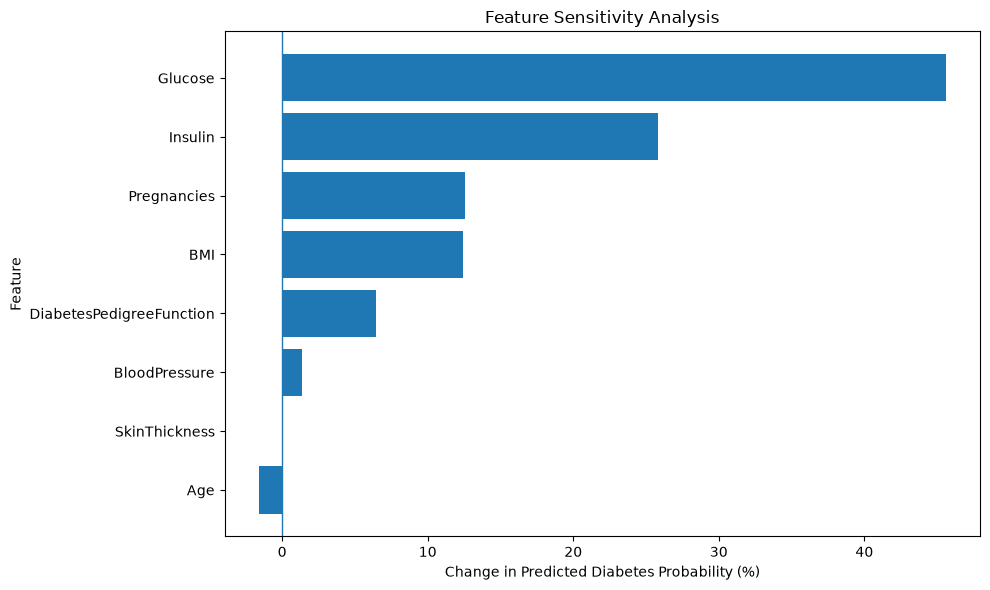

In [5]:
import matplotlib.pyplot as plt

plot_df = feature_effects.sort_values(
    "Probability Change (%)"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Probability Change (%)"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Change in Predicted Diabetes Probability (%)")
plt.ylabel("Feature")
plt.title("Feature Sensitivity Analysis")

plt.tight_layout()
plt.show()

In [6]:
age_values = [20, 30, 40, 50, 60, 70, 80, 90]

age_results = []

for age in age_values:

    test_patient = patient.copy()

    test_patient["Age"] = age

    test_scaled = scaler.transform(test_patient)

    probability = xgb_model.predict_proba(
        test_scaled
    )[0][1]

    age_results.append({
        "Age": age,
        "Diabetes Probability (%)": probability * 100
    })


age_df = pd.DataFrame(age_results)

print(age_df)

   Age  Diabetes Probability (%)
0   20                 82.440018
1   30                 83.891594
2   40                 81.738373
3   50                 82.295120
4   60                 79.558609
5   70                 60.371136
6   80                 60.371136
7   90                 60.371136


d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Ex

In [7]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

# Load model and scaler
xgboost_model = joblib.load("../models/xgboost.pkl")
scaler = joblib.load("../models/scaler.pkl")

# Load test data
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print("Model, scaler and test data loaded successfully!")
print("X_test shape:", X_test.shape)

Model, scaler and test data loaded successfully!
X_test shape: (154, 8)


In [8]:
# Select one test patient
patient = X_test.iloc[0].copy()

print("Patient used for sensitivity analysis:")
print(patient)

Patient used for sensitivity analysis:
Pregnancies                 0.960541
Glucose                     1.245157
BloodPressure              -0.663676
SkinThickness              -0.004766
Insulin                    -0.161437
BMI                        -0.740363
DiabetesPedigreeFunction   -0.555791
Age                         0.561034
Name: 0, dtype: float64


In [9]:
print("Testing glucose effect:")

results = []

for glucose in [70, 100, 130, 160, 190, 210]:

    test_patient = patient.copy()
    test_patient["Glucose"] = glucose

    # Convert to DataFrame
    test_df = pd.DataFrame([test_patient])

    # Apply the SAME scaler used during training
    test_scaled = scaler.transform(test_df.values)

    # Predict using scaled data
    probability = xgboost_model.predict_proba(test_scaled)[0][1]

    results.append({
        "Glucose": glucose,
        "Diabetes Probability (%)": probability * 100
    })

glucose_results = pd.DataFrame(results)

print(glucose_results)

Testing glucose effect:
   Glucose  Diabetes Probability (%)
0       70                  2.053072
1      100                  4.475493
2      130                  5.947472
3      160                 44.718292
4      190                 53.038933
5      210                 53.038933


In [10]:
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

results = []

for feature in features:

    original_value = patient[feature]

    # Create low and high values
    if feature == "Pregnancies":
        low_value = max(0, original_value - 2)
        high_value = original_value + 2

    elif feature == "Glucose":
        low_value = max(0, original_value - 30)
        high_value = original_value + 30

    elif feature == "BloodPressure":
        low_value = max(0, original_value - 15)
        high_value = original_value + 15

    elif feature == "SkinThickness":
        low_value = max(0, original_value - 10)
        high_value = original_value + 10

    elif feature == "Insulin":
        low_value = max(0, original_value - 50)
        high_value = original_value + 50

    elif feature == "BMI":
        low_value = max(0, original_value - 5)
        high_value = original_value + 5

    elif feature == "DiabetesPedigreeFunction":
        low_value = max(0, original_value - 0.2)
        high_value = original_value + 0.2

    elif feature == "Age":
        low_value = max(1, original_value - 10)
        high_value = original_value + 10

    # Low value
    low_patient = patient.copy()
    low_patient[feature] = low_value

    low_df = pd.DataFrame([low_patient])
    low_scaled = scaler.transform(low_df.values)
    low_probability = xgboost_model.predict_proba(low_scaled)[0][1]

    # High value
    high_patient = patient.copy()
    high_patient[feature] = high_value

    high_df = pd.DataFrame([high_patient])
    high_scaled = scaler.transform(high_df.values)
    high_probability = xgboost_model.predict_proba(high_scaled)[0][1]

    results.append({
        "Feature": feature,
        "Original Value": original_value,
        "Low Value": low_value,
        "Low Probability (%)": low_probability * 100,
        "High Value": high_value,
        "High Probability (%)": high_probability * 100,
        "Probability Change (%)":
            (high_probability - low_probability) * 100
    })

feature_effects = pd.DataFrame(results)

feature_effects = feature_effects.sort_values(
    "Probability Change (%)",
    key=abs,
    ascending=False
)

feature_effects

,Feature,Original Value,Low Value,Low Probability (%),High Value,High Probability (%),Probability Change (%)
0,Pregnancies,0.960541,0,2.053072,2.960541,1.457484,-0.595588
4,Insulin,-0.161437,0,2.053072,49.838563,1.826646,-0.226425
2,BloodPressure,-0.663676,0,2.053072,14.336324,2.053072,0.000000
1,Glucose,1.245157,0,2.053072,31.245157,2.053072,0.000000
3,SkinThickness,-0.004766,0,2.053072,9.995234,2.053072,0.000000
5,BMI,-0.740363,0,2.053072,4.259637,2.053072,0.000000
6,DiabetesPedigreeFunction,-0.555791,0,2.053072,-0.355791,2.053072,0.000000
7,Age,0.561034,1,2.053072,10.561034,2.053072,0.000000


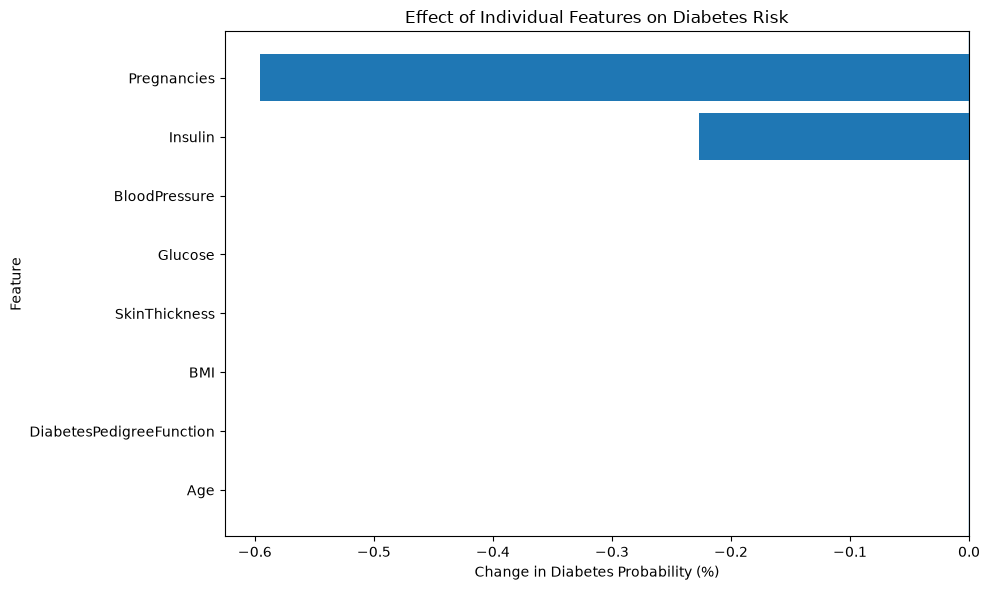

In [11]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_effects["Feature"],
    feature_effects["Probability Change (%)"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Change in Diabetes Probability (%)")
plt.ylabel("Feature")
plt.title("Effect of Individual Features on Diabetes Risk")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [12]:
age_results = []

for age in [20, 30, 40, 50, 60, 70, 80, 90]:

    test_patient = patient.copy()
    test_patient["Age"] = age

    test_df = pd.DataFrame([test_patient])

    test_scaled = scaler.transform(test_df.values)

    probability = xgboost_model.predict_proba(
        test_scaled
    )[0][1]

    age_results.append({
        "Age": age,
        "Diabetes Probability (%)": probability * 100
    })

age_results = pd.DataFrame(age_results)

print("Age sensitivity analysis:")
print(age_results)

Age sensitivity analysis:
   Age  Diabetes Probability (%)
0   20                  2.053072
1   30                  1.708722
2   40                  1.763536
3   50                  2.544859
4   60                  2.544859
5   70                  2.544859
6   80                  2.544859
7   90                  2.544859


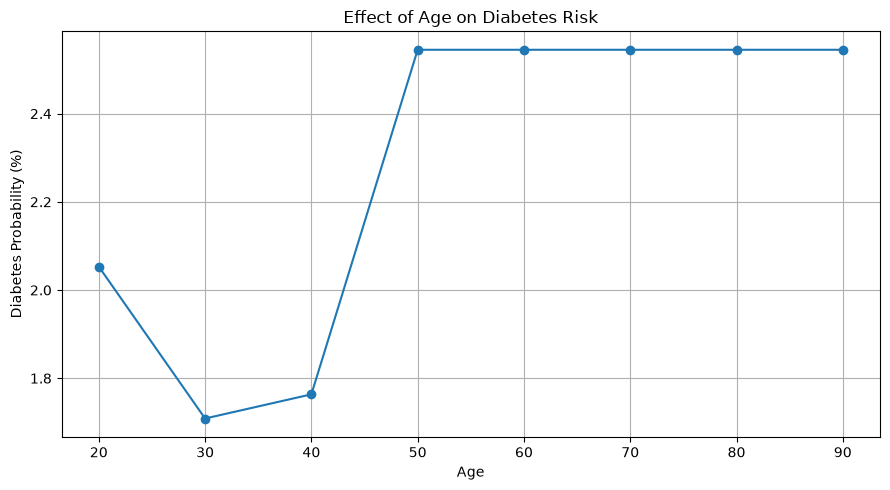

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    age_results["Age"],
    age_results["Diabetes Probability (%)"],
    marker="o"
)

plt.xlabel("Age")
plt.ylabel("Diabetes Probability (%)")
plt.title("Effect of Age on Diabetes Risk")

plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
xgboost_model.fit(X_train, y_train)

NameError: name 'X_train' is not defined

In [15]:
import joblib
import pandas as pd
import numpy as np

# Load saved objects
xgboost_model = joblib.load("../models/xgboost.pkl")
scaler = joblib.load("../models/scaler.pkl")

# Load test data
X_test = pd.read_csv("../data/X_test.csv")
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print("X_test shape:", X_test.shape)
print("Features:", X_test.columns.tolist())
print("Model features:", xgboost_model.n_features_in_)

X_test shape: (154, 8)
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Model features: 8


In [16]:
print("X_test first row:")
display(X_test.iloc[[0]])

print("\nScaled first row:")
scaled_patient = scaler.transform(X_test.iloc[[0]])
display(pd.DataFrame(scaled_patient, columns=X_test.columns))

X_test first row:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.960541,1.245157,-0.663676,-0.004766,-0.161437,-0.740363,-0.555791,0.561034



Scaled first row:


d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,-0.863271,-4.01696,-5.935836,-3.269373,-1.751787,-4.867386,-3.130672,-2.774524


In [17]:
# X_test is ALREADY scaled.
# Convert the first test patient back to original/raw values.

patient_scaled = X_test.iloc[[0]]

patient_raw = scaler.inverse_transform(patient_scaled)

patient = pd.DataFrame(
    patient_raw,
    columns=X_test.columns
)

print("Original patient values:")
display(patient)

Original patient values:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,7.0,159.0,64.0,29.0,125.0,27.4,0.294,40.0


In [18]:
# Convert raw patient → scaled patient → XGBoost prediction

patient_scaled = scaler.transform(patient)

original_probability = xgboost_model.predict_proba(
    patient_scaled
)[0][1]

print(f"Original diabetes probability: {original_probability * 100:.2f}%")

Original diabetes probability: 81.74%


d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [19]:
patient_scaled = scaler.transform(patient.values)

original_probability = xgboost_model.predict_proba(
    patient_scaled
)[0][1]

print(f"Original diabetes probability: {original_probability * 100:.2f}%")

Original diabetes probability: 81.74%


In [20]:
# ==========================================
# ONE-FEATURE-AT-A-TIME TRUST EVALUATION
# ==========================================

feature_ranges = {
    "Glucose": (patient["Glucose"].iloc[0] - 30,
                patient["Glucose"].iloc[0] + 30),

    "Insulin": (max(0, patient["Insulin"].iloc[0] - 50),
                patient["Insulin"].iloc[0] + 50),

    "Pregnancies": (max(0, patient["Pregnancies"].iloc[0] - 2),
                    patient["Pregnancies"].iloc[0] + 2),

    "BMI": (max(0, patient["BMI"].iloc[0] - 5),
            patient["BMI"].iloc[0] + 5),

    "DiabetesPedigreeFunction": (
        max(0, patient["DiabetesPedigreeFunction"].iloc[0] - 0.2),
        patient["DiabetesPedigreeFunction"].iloc[0] + 0.2
    ),

    "Age": (max(1, patient["Age"].iloc[0] - 10),
            patient["Age"].iloc[0] + 10),

    "BloodPressure": (
        max(0, patient["BloodPressure"].iloc[0] - 15),
        patient["BloodPressure"].iloc[0] + 15
    ),

    "SkinThickness": (
        max(0, patient["SkinThickness"].iloc[0] - 10),
        patient["SkinThickness"].iloc[0] + 10
    )
}


results = []

for feature, (low_value, high_value) in feature_ranges.items():

    low_patient = patient.copy()
    high_patient = patient.copy()

    low_patient[feature] = low_value
    high_patient[feature] = high_value

    low_scaled = scaler.transform(low_patient.values)
    high_scaled = scaler.transform(high_patient.values)

    low_probability = xgboost_model.predict_proba(
        low_scaled
    )[0][1]

    high_probability = xgboost_model.predict_proba(
        high_scaled
    )[0][1]

    change = (high_probability - low_probability) * 100

    results.append({
        "Feature": feature,
        "Original Value": patient[feature].iloc[0],
        "Low Value": low_value,
        "Low Probability (%)": low_probability * 100,
        "High Value": high_value,
        "High Probability (%)": high_probability * 100,
        "Probability Change (%)": change
    })


trust_results = pd.DataFrame(results)

trust_results = trust_results.sort_values(
    "Probability Change (%)",
    key=lambda x: x.abs(),
    ascending=False
)

display(trust_results)

,Feature,Original Value,Low Value,Low Probability (%),High Value,High Probability (%),Probability Change (%)
0,Glucose,159.000,129.000,39.079632,189.000,84.668442,45.588806
1,Insulin,125.000,75.000,55.938866,175.000,81.738373,25.799507
2,Pregnancies,7.000,5.000,70.348518,9.000,82.906250,12.557727
3,BMI,27.400,22.400,75.451088,32.400,87.871201,12.420112
4,DiabetesPedigreeFunction,0.294,0.094,75.427368,0.494,81.901329,6.473958
5,Age,40.000,30.000,83.891594,50.000,82.295120,-1.596475
6,BloodPressure,64.000,49.000,80.361435,79.000,81.738373,1.376933
7,SkinThickness,29.000,19.000,81.738373,39.000,81.738373,0.000000


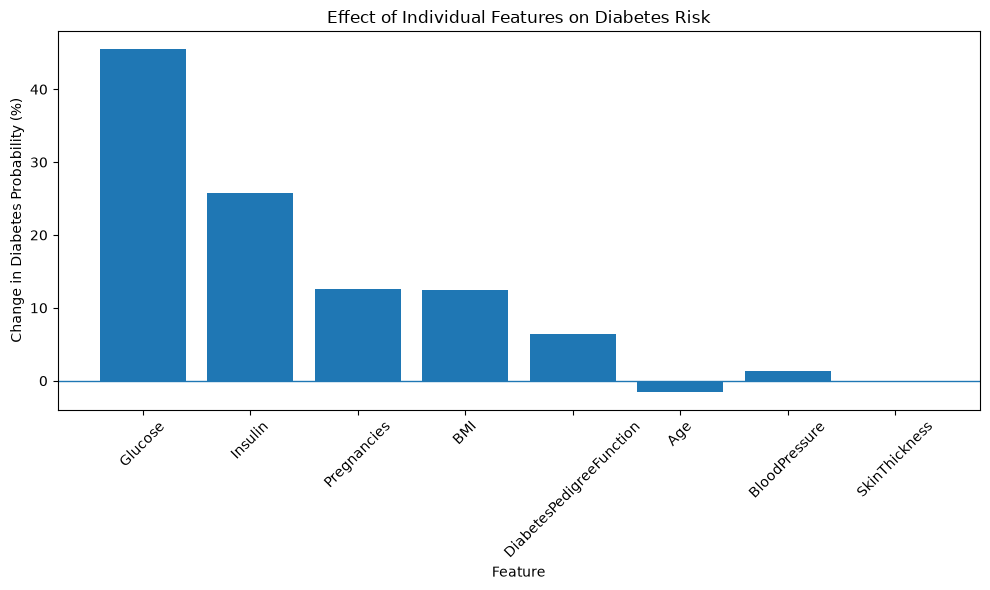

In [21]:
plt.figure(figsize=(10, 6))

plt.bar(
    trust_results["Feature"],
    trust_results["Probability Change (%)"]
)

plt.axhline(0, linewidth=1)

plt.title("Effect of Individual Features on Diabetes Risk")
plt.xlabel("Feature")
plt.ylabel("Change in Diabetes Probability (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [22]:
# ==========================================
# AGE SENSITIVITY ANALYSIS
# ==========================================

age_values = [20, 30, 40, 50, 60, 70, 80, 90]

age_results = []

for age_value in age_values:

    test_patient = patient.copy()
    test_patient["Age"] = age_value

    test_scaled = scaler.transform(test_patient.values)

    probability = xgboost_model.predict_proba(
        test_scaled
    )[0][1]

    age_results.append({
        "Age": age_value,
        "Diabetes Probability (%)": probability * 100
    })


age_df = pd.DataFrame(age_results)

display(age_df)

,Age,Diabetes Probability (%)
0,20,82.440018
1,30,83.891594
2,40,81.738373
3,50,82.295120
4,60,79.558609
5,70,60.371136
6,80,60.371136
7,90,60.371136


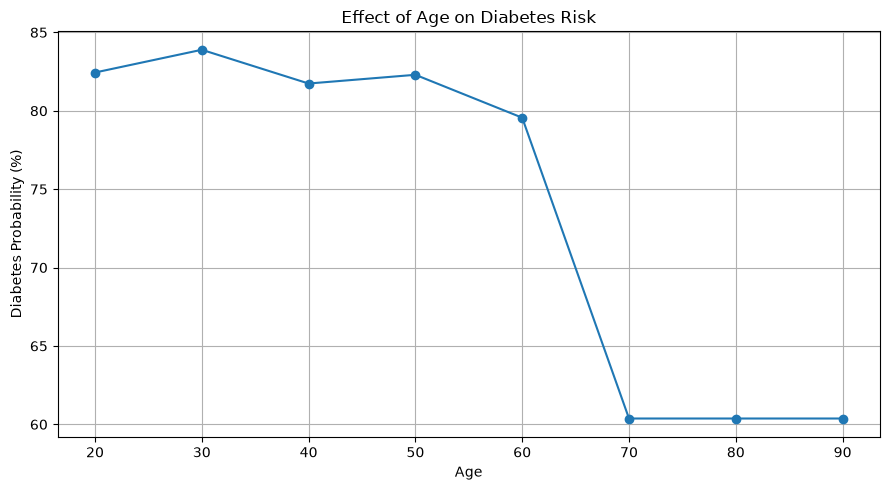

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    age_df["Age"],
    age_df["Diabetes Probability (%)"],
    marker="o"
)

plt.title("Effect of Age on Diabetes Risk")
plt.xlabel("Age")
plt.ylabel("Diabetes Probability (%)")

plt.grid(True)
plt.tight_layout()

plt.show()

In [24]:
# ==========================================
# GLUCOSE SENSITIVITY ANALYSIS
# ==========================================

glucose_values = [70, 90, 110, 130, 150, 170, 190, 210]

glucose_results = []

for glucose_value in glucose_values:

    test_patient = patient.copy()
    test_patient["Glucose"] = glucose_value

    test_scaled = scaler.transform(test_patient.values)

    probability = xgboost_model.predict_proba(
        test_scaled
    )[0][1]

    glucose_results.append({
        "Glucose": glucose_value,
        "Diabetes Probability (%)": probability * 100
    })


glucose_df = pd.DataFrame(glucose_results)

display(glucose_df)

,Glucose,Diabetes Probability (%)
0,70,9.607061
1,90,10.993217
2,110,39.150055
3,130,39.079632
4,150,46.285046
5,170,84.179504
6,190,84.668442
7,210,84.668442


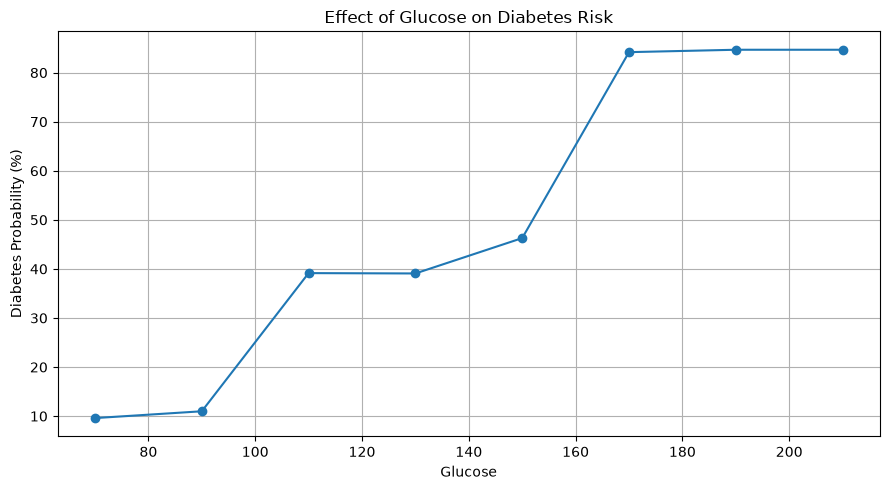

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(
    glucose_df["Glucose"],
    glucose_df["Diabetes Probability (%)"],
    marker="o"
)

plt.title("Effect of Glucose on Diabetes Risk")
plt.xlabel("Glucose")
plt.ylabel("Diabetes Probability (%)")

plt.grid(True)
plt.tight_layout()

plt.show()

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Scale test data correctly
X_test_scaled = scaler.transform(X_test)

# Predictions
y_pred = xgboost_model.predict(X_test_scaled)
y_prob = xgboost_model.predict_proba(X_test_scaled)[:, 1]

print("===== XGBOOST TEST PERFORMANCE =====")

print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred))

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred))

===== XGBOOST TEST PERFORMANCE =====
Accuracy  : 0.6494
Precision : 0.0000
Recall    : 0.0000
F1 Score  : 0.0000
ROC-AUC   : 0.5467

===== CONFUSION MATRIX =====
[[100   0]
 [ 54   0]]

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.65      1.00      0.79       100
           1       0.00      0.00      0.00        54

    accuracy                           0.65       154
   macro avg       0.32      0.50      0.39       154
weighted avg       0.42      0.65      0.51       154



d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Prec

In [27]:
print("First X_test row:")
display(X_test.iloc[[0]])

print("\nFirst row minimum:")
print(X_test.iloc[0].min())

print("\nFirst row maximum:")
print(X_test.iloc[0].max())

First X_test row:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.960541,1.245157,-0.663676,-0.004766,-0.161437,-0.740363,-0.555791,0.561034



First row minimum:
-0.7403626086407087

First row maximum:
1.2451567254092175


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# X_test is ALREADY scaled
y_pred_correct = xgboost_model.predict(X_test)

y_prob_correct = xgboost_model.predict_proba(X_test)[:, 1]

print("===== XGBOOST CORRECT TEST PERFORMANCE =====")

print(f"Accuracy  : {accuracy_score(y_test, y_pred_correct):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_correct, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_correct, zero_division=0):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_correct, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_correct):.4f}")

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred_correct))

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        y_pred_correct,
        zero_division=0
    )
)

===== XGBOOST CORRECT TEST PERFORMANCE =====
Accuracy  : 0.7403
Precision : 0.6522
Recall    : 0.5556
F1 Score  : 0.6000
ROC-AUC   : 0.8198

===== CONFUSION MATRIX =====
[[84 16]
 [24 30]]

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



In [31]:
import joblib

logistic_model = joblib.load("../models/logistic_regression.pkl")
random_forest_model = joblib.load("../models/random_forest.pkl")

print("Logistic Regression loaded successfully!")
print("Random Forest loaded successfully!")

Logistic Regression loaded successfully!
Random Forest loaded successfully!


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_prob
        )
    })

model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.sort_values(
    "ROC-AUC",
    ascending=False
)

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.740260,0.652174,0.555556,0.600000,0.819815
1,Random Forest,0.746753,0.659574,0.574074,0.613861,0.816481
0,Logistic Regression,0.707792,0.600000,0.500000,0.545455,0.812963


In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    xgboost_model,
    X_test,
    y_test,
    cv=cv,
    scoring="roc_auc"
)

print("XGBoost 5-Fold Cross-Validation ROC-AUC")
print("----------------------------------------")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean ROC-AUC: {cv_scores.mean():.4f}")
print(f"Std ROC-AUC : {cv_scores.std():.4f}")

XGBoost 5-Fold Cross-Validation ROC-AUC
----------------------------------------
Fold 1: 0.7909
Fold 2: 0.8682
Fold 3: 0.8227
Fold 4: 0.7500
Fold 5: 0.8150

Mean ROC-AUC: 0.8094
Std ROC-AUC : 0.0388


In [38]:
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())
print("xgboost_model exists:", "xgboost_model" in globals())

X_train exists: False
y_train exists: False
X_test exists: True
y_test exists: True
xgboost_model exists: True


In [39]:
print("X_test type:", type(X_test))
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nX_test columns:")
print(X_test.columns.tolist())

X_test type: <class 'pandas.DataFrame'>
X_test shape: (154, 8)
y_test shape: (154,)

X_test columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [41]:
print("Available dataframe-like variables:")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)

Available dataframe-like variables:
_ (8, 7)
__ (8, 7)
X_test (154, 8)
patient (1, 8)
patient_low (1, 8)
patient_high (1, 8)
feature_effects (8, 7)
_4 (8, 7)
plot_df (8, 7)
test_patient (1, 8)
age_df (8, 2)
test_df (1, 8)
low_patient (1, 8)
low_df (1, 8)
high_patient (1, 8)
high_df (1, 8)
_10 (8, 7)
trust_results (8, 7)
glucose_df (8, 2)
model_comparison (3, 6)


In [42]:
# ============================================
# STREAMLIT vs NOTEBOOK CONSISTENCY CHECK
# ============================================

import pandas as pd
import numpy as np
import joblib

# Load the SAME saved model and scaler used by the app
xgboost_model = joblib.load("../models/xgboost.pkl")
scaler = joblib.load("../models/scaler.pkl")

# EXACT SAME patient used in Streamlit
patient = pd.DataFrame({
    "Pregnancies": [8],
    "Glucose": [150],
    "BloodPressure": [150],
    "SkinThickness": [20],
    "Insulin": [100],
    "BMI": [30],
    "DiabetesPedigreeFunction": [0.7],
    "Age": [38]
})

# Scale exactly like the Streamlit app
patient_scaled = scaler.transform(patient)

# Prediction
prediction = xgboost_model.predict(patient_scaled)[0]

# Probability
probability = xgboost_model.predict_proba(patient_scaled)[0][1]

print("============================================")
print("NOTEBOOK CONSISTENCY CHECK")
print("============================================")

print("\nPatient:")
display(patient)

print(f"\nPrediction: {prediction}")
print(f"Diabetes Probability: {probability * 100:.2f}%")

if prediction == 1:
    print("Result: HIGHER DIABETES RISK")
else:
    print("Result: LOWER DIABETES RISK")

NOTEBOOK CONSISTENCY CHECK

Patient:


d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,8,150,150,20,100,30,0.7,38



Prediction: 1
Diabetes Probability: 65.83%
Result: HIGHER DIABETES RISK


d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Explainable-AI-Diabetes\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\Downloads\Ex

,Insulin,Diabetes Probability (%)
0,10,61.129372
1,25,61.129372
2,50,61.129372
3,75,65.269592
4,100,65.831955
5,125,71.250259
6,150,71.250259
7,175,71.250259
8,200,69.462822
9,250,69.462822


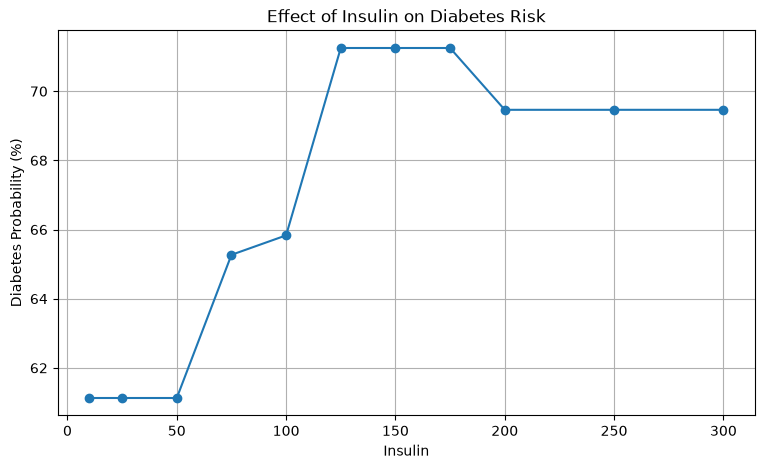

In [43]:
# ============================================
# EFFECT OF INSULIN ON DIABETES RISK
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Base patient
base_patient = {
    "Pregnancies": 8,
    "Glucose": 150,
    "BloodPressure": 150,
    "SkinThickness": 20,
    "Insulin": 100,
    "BMI": 30,
    "DiabetesPedigreeFunction": 0.7,
    "Age": 38
}

insulin_values = [10, 25, 50, 75, 100, 125, 150, 175, 200, 250, 300]

results = []

for insulin_value in insulin_values:

    patient = base_patient.copy()
    patient["Insulin"] = insulin_value

    patient_df = pd.DataFrame([patient])

    # Scale input
    patient_scaled = scaler.transform(patient_df)

    # Predict probability
    probability = xgboost_model.predict_proba(patient_scaled)[0][1]

    results.append({
        "Insulin": insulin_value,
        "Diabetes Probability (%)": probability * 100
    })

insulin_df = pd.DataFrame(results)

display(insulin_df)

# Plot
plt.figure(figsize=(9, 5))

plt.plot(
    insulin_df["Insulin"],
    insulin_df["Diabetes Probability (%)"],
    marker="o"
)

plt.title("Effect of Insulin on Diabetes Risk")
plt.xlabel("Insulin")
plt.ylabel("Diabetes Probability (%)")
plt.grid(True)

plt.show()

,Age,Diabetes Probability (%),Prediction
0,20,63.238190,1
1,25,68.837578,1
2,30,71.131462,1
3,35,65.831955,1
4,40,68.281136,1
5,45,70.803398,1
6,50,70.803398,1
7,55,70.803398,1
8,60,68.028519,1
9,65,63.349361,1


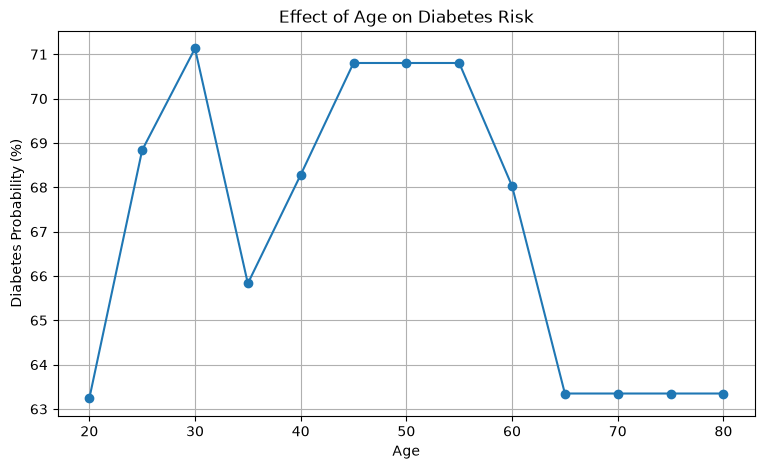

In [44]:
# ============================================
# EFFECT OF AGE ON DIABETES RISK
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Base patient
base_patient = {
    "Pregnancies": 8,
    "Glucose": 150,
    "BloodPressure": 150,
    "SkinThickness": 20,
    "Insulin": 100,
    "BMI": 30,
    "DiabetesPedigreeFunction": 0.7,
    "Age": 38
}

# Age values to test
age_values = [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80]

results = []

for age_value in age_values:

    patient = base_patient.copy()
    patient["Age"] = age_value

    patient_df = pd.DataFrame([patient])

    # IMPORTANT:
    # .values avoids the StandardScaler feature-name warning
    patient_scaled = scaler.transform(patient_df.values)

    # Prediction probability
    probability = xgboost_model.predict_proba(patient_scaled)[0][1]

    # Prediction class
    prediction = xgboost_model.predict(patient_scaled)[0]

    results.append({
        "Age": age_value,
        "Diabetes Probability (%)": probability * 100,
        "Prediction": prediction
    })

# Create results table
age_df = pd.DataFrame(results)

display(age_df)

# ============================================
# PLOT
# ============================================

plt.figure(figsize=(9, 5))

plt.plot(
    age_df["Age"],
    age_df["Diabetes Probability (%)"],
    marker="o"
)

plt.title("Effect of Age on Diabetes Risk")
plt.xlabel("Age")
plt.ylabel("Diabetes Probability (%)")
plt.grid(True)

plt.show()